In [3]:
!pip install "numpy<2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 5.1 MB/s eta 0:00:00m eta 0:00:010:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Importing the DATASET

In [28]:
# Importing the dataset
# forcing CHROM to be read as a string to avoid mixed-type warnings
data = pd.read_csv('/home/lakki4403/Documents/ML/clinvar.csv', dtype={'CHROM': str})
pre_encoded_cols = ['Target', 'CHROM_Encoded', 'VT_Encoded', 'Unnamed: 0']
data = data.drop(columns=[col for col in pre_encoded_cols if col in data.columns])

## Looking at the raw dataset

In [29]:
# Raw Dataset
from IPython.display import display
# Display the first few rows as a clean HTML table
display(data.head(10))

,CHROM,POS,ID,REF,ALT,QUAL,FILTER,INFO,CLNSIG,Varyant_Tipi
0,1,69134,2205837,A,G,.,.,"ALLELEID=2193183;CLNDISDB=MedGen:CN169374;CLNDN=not_specified;CLNHGVS=NC_000001.10:g.69134A>G;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV003526545;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:CA502008;GENEINFO=OR4F5:79501;MC=SO:0001583|missense_variant;ORIGIN=1;RS=781394307",Likely_benign,SO:0001583|missense_variant
1,1,744664,3892489,T,TGGTCAATCA,.,.,"ALLELEID=4008375;CLNDISDB=MONDO:MONDO:0100428,MedGen:C0393540,OMIM:211500|MONDO:MONDO:0024537,MedGen:C0796274,OMIM:211530,Orphanet:572543,Orphanet:97229;CLNDN=Progressive_bulbar_palsy_of_childhood|Brown-Vialetto-van_Laere_syndrome_1;CLNHGVS=NC_000001.10:g.744669_744670insATCAGGTCA;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Benign;CLNSIGSCV=SCV006059617;CLNVC=Insertion;CLNVCSO=SO:0000667;GENEINFO=LINC01409:105378580;ORIGIN=1",Benign,UNKNOWN
2,1,859898,3388928,G,C,.,.,"ALLELEID=3548054;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.859898G>C;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV005435063;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;GENEINFO=SAMD11:148398|LOC107985728:107985728;MC=SO:0001819|synonymous_variant;ORIGIN=1",Likely_benign,SO:0001819|synonymous_variant
3,1,861336,1543320,C,T,.,.,"ALLELEID=1632777;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861336C>T;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV002335012;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:CA415378520;GENEINFO=SAMD11:148398;MC=SO:0001819|synonymous_variant;ORIGIN=1;RS=1342334044",Likely_benign,SO:0001819|synonymous_variant
4,1,861349,1648427,C,T,.,.,"AF_EXAC=0.00033;ALLELEID=1600580;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861349C>T;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV002470140;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:CA502382;GENEINFO=SAMD11:148398;MC=SO:0001583|missense_variant;ORIGIN=1;RS=200686669",Likely_benign,SO:0001583|missense_variant
5,1,861360,1936488,C,T,.,.,"ALLELEID=1986319;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861360C>T;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV002977672;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:CA16702505;GENEINFO=SAMD11:148398;MC=SO:0001819|synonymous_variant;ORIGIN=1;RS=931465641",Likely_benign,SO:0001819|synonymous_variant
6,1,861366,1568423,C,T,.,.,"ALLELEID=1570515;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861366C>T;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV002368344;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:CA415378554;GENEINFO=SAMD11:148398;MC=SO:0001819|synonymous_variant;ORIGIN=1;RS=1640864832",Likely_benign,SO:0001819|synonymous_variant
7,1,861390,1632958,G,T,.,.,"ALLELEID=1545352;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861390G>T;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV002441628;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:CA415378577;GENEINFO=SAMD11:148398;MC=SO:0001819|synonymous_variant;ORIGIN=1;RS=889842126",Likely_benign,SO:0001819|synonymous_variant
8,1,861402,4704304,C,G,.,.,"ALLELEID=4804963;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861402C>G;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV007363944;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;GENEINFO=SAMD11:148398;MC=SO:0001627|intron_variant;ORIGIN=1",Likely_benign,SO:0001627|intron_variant
9,1,861405,1555362,G,A,.,.,"ALLELEID=1550067;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861405G>A;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV00235

### INFO col has aggreagted various possibly useful information into a single col. 
### Lets look into how many diff information the entire dataset has

In [30]:
# 1. Parse all key-value pairs into a list of dictionaries
def parse_all_info(info_str):
    if pd.isna(info_str):
        return {}
    pairs = info_str.split(';')
    info_dict = {}
    for pair in pairs:
        if '=' in pair:
            key, value = pair.split('=', 1)
            info_dict[key] = value
    return info_dict

# Convert list of dicts to a DataFrame
all_info_df = pd.DataFrame(data['INFO'].apply(parse_all_info).tolist())

# 2. Check which keys actually show up and how common they are (non-null counts)
print("--- Available INFO Keys and Non-Null Counts ---")
print(all_info_df.notnull().sum()[all_info_df.notnull().sum() > 0])

--- Available INFO Keys and Non-Null Counts ---
ALLELEID        1686794
CLNDISDB        1686794
CLNDN           1686794
CLNHGVS         1686657
CLNREVSTAT      1686794
CLNSIG          1686794
CLNSIGSCV       1686794
CLNVC           1686794
CLNVCSO         1686794
CLNVI           1391305
GENEINFO        1686455
MC              1676519
ORIGIN          1686794
RS              1397611
AF_EXAC          431618
AF_TGP           307150
AF_ESP           216925
CLNDISDBINCL        679
CLNDNINCL           679
CLNSIGINCL          679
SCI                 420
SCIDISDB            420
SCIDN               420
SCIREVSTAT          420
SCISCV              420
ONC                 651
ONCDISDB            651
ONCDN               651
ONCREVSTAT          651
ONCSCV              651
DBVARID             130
ONCCONF               1
dtype: int64


### After Looking into the info column. we are gonna drop the info that can only help cherrypicked cases or outliers. And Pick the following:
ALLELEID        1686794 <br>
CLNDISDB        1686794 <br>
CLNDN           1686794 <br>
CLNHGVS         1686657 <br>
CLNREVSTAT      1686794 <br>
CLNSIG          1686794 <br>
CLNSIGSCV       1686794 <br>
CLNVC           1686794 <br>
CLNVCSO         1686794 <br>
CLNVI           1391305 <br>
GENEINFO        1686455 <br>
MC              1676519 <br>
ORIGIN          1686794 <br>
RS              1397611 <br>
AF_EXAC          431618 <br>
AF_TGP           307150 <br>
AF_ESP           216925 <br>
##### has nearly every case seem to use these features.
##### However these too contain two different infos as follows:
### 1. The "Corporate IDs" & Metadata (Drop or Exclude)
#### These columns exist for database tracking, cross-referencing, or literature citations, but they have no predictive biological value for a machine learning model:
#### ALLELEID: Purely an internal database primary key.
#### RS (dbSNP ID): High-cardinality identifier (every variant has a unique ID). Models cannot generalize from random ID numbers.
#### CLNSIGSCV: Individual submitter accession numbers (SCV codes). Pure administrative metadata.
#### CLNVI: Internal ClinVar variation links.
#### CLNHGVS: Text-based exact coordinate description. Since you already have CHROM, POS, REF, and ALT, this is redundant text.

### 2. The High-Value Predictive Features (Keep!)
#### Your shortlist is spot-on. These capture population statistics, structural impacts, and biological consequences:
#### Allele Frequencies (AF_EXAC, AF_TGP, AF_ESP): Critical. Common variants in human populations are almost always benign, while disease-causing variants are typically ultra-rare or absent.
#### Molecular Consequence (MC): Critical. Tells the model how the variant affects the protein or transcript (e.g., missense_variant, synonymous_variant, stop_gained), which strongly correlates with pathogenicity.
#### Variant Type (CLNVC & CLNVCSO): Tells the model whether it's a single nucleotide variant (SNV), insertion, or deletion.
#### GENEINFO: The gene symbol (e.g., BRCA1), which helps the model learn if certain genes are more prone to pathogenic variants.

#### Hemce, clearly the corporate IDs arent gonna help our model. So we'll select the features in the second category



In [31]:
target_keys = [
    'CLNVC', 'CLNVCSO', 'GENEINFO', 
    'MC', 'AF_EXAC', 'AF_TGP', 'AF_ESP'
]

def extract_all_specified_info(info_str):
    if pd.isna(info_str):
        return {key: None for key in target_keys}
    
    pairs = info_str.split(';')
    info_dict = {}
    for pair in pairs:
        if '=' in pair:
            key, value = pair.split('=', 1)
            info_dict[key] = value
            
    # Map values to our target keys
    result = {}
    for key in target_keys:
        val = info_dict.get(key, None)
        
        # Convert allele frequencies to floats, default missing ones to 0.0
        if key in ['AF_EXAC', 'AF_TGP', 'AF_ESP']:
            try:
                result[key] = float(val) if val is not None else 0.0
            except ValueError:
                result[key] = 0.0
        else:
            result[key] = val
            
    return result  

# Apply the extraction across the dataset
extracted_features = pd.DataFrame(data['INFO'].apply(extract_all_specified_info).tolist())

# Merge the extracted features back to your main dataframe
data_cleaned = pd.concat([data.reset_index(drop=True), extracted_features.reset_index(drop=True)], axis=1)

print("Successfully extracted all requested INFO fields!")
print("New Dataset Shape:", data_cleaned.shape)

Successfully extracted all requested INFO fields!
New Dataset Shape: (1686794, 17)


# Cleaning Our Extracted Dataset

In [32]:
# Temporarily allow pandas to display full string lengths
pd.set_option('display.max_colwidth', None)
display(data_cleaned.head(10))
# display(data_cleaned[['INFO']].head(5))

,CHROM,POS,ID,REF,ALT,QUAL,FILTER,INFO,CLNSIG,Varyant_Tipi,CLNVC,CLNVCSO,GENEINFO,MC,AF_EXAC,AF_TGP,AF_ESP
0,1,69134,2205837,A,G,.,.,"ALLELEID=2193183;CLNDISDB=MedGen:CN169374;CLNDN=not_specified;CLNHGVS=NC_000001.10:g.69134A>G;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV003526545;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:CA502008;GENEINFO=OR4F5:79501;MC=SO:0001583|missense_variant;ORIGIN=1;RS=781394307",Likely_benign,SO:0001583|missense_variant,single_nucleotide_variant,SO:0001483,OR4F5:79501,SO:0001583|missense_variant,0.00000,0.0,0.0
1,1,744664,3892489,T,TGGTCAATCA,.,.,"ALLELEID=4008375;CLNDISDB=MONDO:MONDO:0100428,MedGen:C0393540,OMIM:211500|MONDO:MONDO:0024537,MedGen:C0796274,OMIM:211530,Orphanet:572543,Orphanet:97229;CLNDN=Progressive_bulbar_palsy_of_childhood|Brown-Vialetto-van_Laere_syndrome_1;CLNHGVS=NC_000001.10:g.744669_744670insATCAGGTCA;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Benign;CLNSIGSCV=SCV006059617;CLNVC=Insertion;CLNVCSO=SO:0000667;GENEINFO=LINC01409:105378580;ORIGIN=1",Benign,UNKNOWN,Insertion,SO:0000667,LINC01409:105378580,None,0.00000,0.0,0.0
2,1,859898,3388928,G,C,.,.,"ALLELEID=3548054;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.859898G>C;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV005435063;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;GENEINFO=SAMD11:148398|LOC107985728:107985728;MC=SO:0001819|synonymous_variant;ORIGIN=1",Likely_benign,SO:0001819|synonymous_variant,single_nucleotide_variant,SO:0001483,SAMD11:148398|LOC107985728:107985728,SO:0001819|synonymous_variant,0.00000,0.0,0.0
3,1,861336,1543320,C,T,.,.,"ALLELEID=1632777;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861336C>T;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV002335012;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:CA415378520;GENEINFO=SAMD11:148398;MC=SO:0001819|synonymous_variant;ORIGIN=1;RS=1342334044",Likely_benign,SO:0001819|synonymous_variant,single_nucleotide_variant,SO:0001483,SAMD11:148398,SO:0001819|synonymous_variant,0.00000,0.0,0.0
4,1,861349,1648427,C,T,.,.,"AF_EXAC=0.00033;ALLELEID=1600580;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861349C>T;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV002470140;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:CA502382;GENEINFO=SAMD11:148398;MC=SO:0001583|missense_variant;ORIGIN=1;RS=200686669",Likely_benign,SO:0001583|missense_variant,single_nucleotide_variant,SO:0001483,SAMD11:148398,SO:0001583|missense_variant,0.00033,0.0,0.0
5,1,861360,1936488,C,T,.,.,"ALLELEID=1986319;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861360C>T;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV002977672;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:CA16702505;GENEINFO=SAMD11:148398;MC=SO:0001819|synonymous_variant;ORIGIN=1;RS=931465641",Likely_benign,SO:0001819|synonymous_variant,single_nucleotide_variant,SO:0001483,SAMD11:148398,SO:0001819|synonymous_variant,0.00000,0.0,0.0
6,1,861366,1568423,C,T,.,.,"ALLELEID=1570515;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861366C>T;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV002368344;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:CA415378554;GENEINFO=SAMD11:148398;MC=SO:0001819|synonymous_variant;ORIGIN=1;RS=1640864832",Likely_benign,SO:0001819|synonymous_variant,single_nucleotide_variant,SO:0001483,SAMD11:148398,SO:0001819|synonymous_variant,0.00000,0.0,0.0
7,1,861390,1632958,G,T,.,.,"ALLELEID=1545352;CLNDISDB=MedGen:C3661900;CLNDN=not_provided;CLNHGVS=NC_000001.10:g.861390G>T;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Likely_benign;CLNSIGSCV=SCV002441628;CLNVC=single_nucleotide_variant;CLNVCSO=SO:0001483;CLNVI=ClinGen:

### Dropping Empty Columns. These Columns either contribute to clutter, are completely empty throughout or their are not enough values to consider an imputation.

In [39]:
# Drop raw INFO, redundant code columns, and duplicate text columns
cols_to_drop = ['INFO', 'CLNVCSO', 'Varyant_Tipi', 'ID', 'QUAL', 'FILTER']
data_ready = data_cleaned.drop(columns=[col for col in cols_to_drop if col in data_cleaned.columns])

In [34]:
display(data_ready.head(10))

,CHROM,POS,REF,ALT,CLNSIG,CLNVC,GENEINFO,MC,AF_EXAC,AF_TGP,AF_ESP
0,1,69134,A,G,Likely_benign,single_nucleotide_variant,OR4F5:79501,SO:0001583|missense_variant,0.00000,0.0,0.0
1,1,744664,T,TGGTCAATCA,Benign,Insertion,LINC01409:105378580,None,0.00000,0.0,0.0
2,1,859898,G,C,Likely_benign,single_nucleotide_variant,SAMD11:148398|LOC107985728:107985728,SO:0001819|synonymous_variant,0.00000,0.0,0.0
3,1,861336,C,T,Likely_benign,single_nucleotide_variant,SAMD11:148398,SO:0001819|synonymous_variant,0.00000,0.0,0.0
4,1,861349,C,T,Likely_benign,single_nucleotide_variant,SAMD11:148398,SO:0001583|missense_variant,0.00033,0.0,0.0
5,1,861360,C,T,Likely_benign,single_nucleotide_variant,SAMD11:148398,SO:0001819|synonymous_variant,0.00000,0.0,0.0
6,1,861366,C,T,Likely_benign,single_nucleotide_variant,SAMD11:148398,SO:0001819|synonymous_variant,0.00000,0.0,0.0
7,1,861390,G,T,Likely_benign,single_nucleotide_variant,SAMD11:148398,SO:0001819|synonymous_variant,0.00000,0.0,0.0
8,1,861402,C,G,Likely_benign,single_nucleotide_variant,SAMD11:148398,SO:0001627|intron_variant,0.00000,0.0,0.0
9,1,861405,G,A,Likely_benign,single_nucleotide_variant,SAMD11:148398,SO:0001627|intron_variant,0.00000,0.0,0.0


#### The GENEINFO column pairs the gene symbol with its Entrez ID (e.g., OR4F5:79501), and occasionally has multiple overlapping genes separated by |. For a clean feature, we usually want to extract just the primary gene symbol (the first one before the colon).


In [35]:
def clean_geneinfo(gene_str):
    if pd.isna(gene_str):
        return 'Unknown'
    # If there are multiple genes separated by '|', take the first one
    first_entry = gene_str.split('|')[0]
    # Split 'OR4F5:79501' by ':' and keep just the symbol ('OR4F5')
    if ':' in first_entry:
        return first_entry.split(':')[0]
    return first_entry

data_cleaned['Primary_Gene'] = data_ready['GENEINFO'].apply(clean_geneinfo)

# Drop the old raw columns and check the clean results
data_ready = data_ready.drop(columns=['MC', 'GENEINFO'])

#### The MC column combines a Sequence Ontology code with the human-readable consequence (e.g., SO:0001583|missense_variant). Lets split them by the pipe (|) and keep just the clean text description.

In [40]:
def clean_mc(mc_str):
    if pd.isna(mc_str) or mc_str == 'None':
        return 'Unknown'
    
    # Split by comma and take only the very first consequence
    first_part = str(mc_str).split(',')[0]
    
    # Extract the human-readable text after the pipe '|' if it exists
    if '|' in first_part:
        return first_part.split('|', 1)[1]
        
    return first_part

# FIXED: Apply it to the original 'MC' column and store it in 'MC_Clean'
data_ready['MC_Clean'] = data_ready['MC'].apply(clean_mc)

# Verify that there are NO commas left anywhere in MC_Clean
print("Any commas remaining?", data_ready['MC_Clean'].str.contains(',').any())
print("Unique clean consequences:", data_ready['MC_Clean'].unique())

Any commas remaining? False
Unique clean consequences: ['missense_variant' 'Unknown' 'synonymous_variant' 'intron_variant'
 'splice_donor_variant' 'nonsense' 'splice_acceptor_variant'
 '5_prime_UTR_variant' 'frameshift_variant' '3_prime_UTR_variant'
 'genic_upstream_transcript_variant' 'inframe_deletion'
 'initiator_codon_variant' 'inframe_insertion'
 'non-coding_transcript_variant' 'genic_downstream_transcript_variant'
 'inframe_indel' 'stop_lost' 'no_sequence_alteration']


# Exploratory Analysis

In [41]:
print("total rows and columns")
print(data_ready.shape)
print("\n", "=="*24)
# print("Data types and non-null counts")
print(data_ready.info())
print("\n", "=="*24)
print("Summary Statistics for numerical columns")
print(data_ready.describe())
print("\n", "=="*24)

total rows and columns
(1686794, 13)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1686794 entries, 0 to 1686793
Data columns (total 13 columns):
 #   Column        Non-Null Count    Dtype  
---  ------        --------------    -----  
 0   CHROM         1686794 non-null  object 
 1   POS           1686794 non-null  int64  
 2   REF           1686794 non-null  object 
 3   ALT           1686794 non-null  object 
 4   CLNSIG        1686794 non-null  object 
 5   CLNVC         1686794 non-null  object 
 6   GENEINFO      1686455 non-null  object 
 7   MC            1676519 non-null  object 
 8   AF_EXAC       1686794 non-null  float64
 9   AF_TGP        1686794 non-null  float64
 10  AF_ESP        1686794 non-null  float64
 11  Primary_Gene  1686794 non-null  object 
 12  MC_Clean      1686794 non-null  object 
dtypes: float64(3), int64(1), object(9)
memory usage: 167.3+ MB
None

Summary Statistics for numerical columns
                POS       AF_EXAC        AF_TGP        AF_ESP
c

In [42]:
# Check unique values and counts for clinical significance labels
print("--- CLNSIG Value Counts ---")
print(data_cleaned['CLNSIG'].value_counts())

--- CLNSIG Value Counts ---
CLNSIG
Likely_benign                   1081389
Benign                           209662
Pathogenic                       185024
Likely_pathogenic                110549
Benign/Likely_benign              63543
Pathogenic/Likely_pathogenic      36627
Name: count, dtype: int64


CLNSIG
Likely_benign                   1081389
Benign                           209662
Pathogenic                       185024
Likely_pathogenic                110549
Benign/Likely_benign              63543
Pathogenic/Likely_pathogenic      36627
Name: count, dtype: int64


<Axes: xlabel='CLNSIG'>

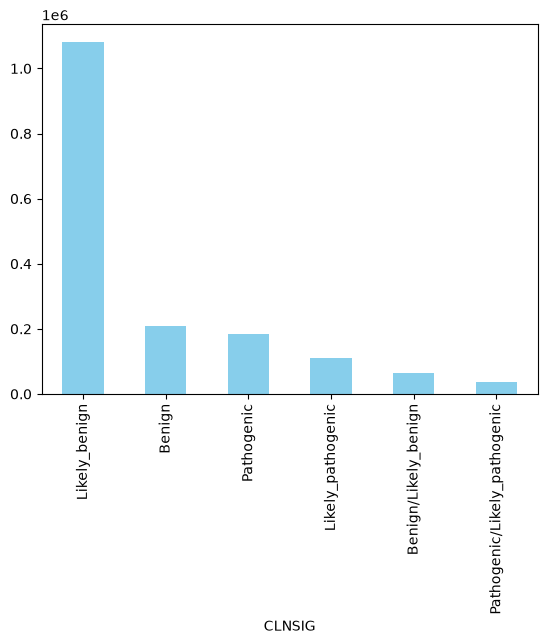

In [43]:
# Target Value Distribution
print(data_cleaned['CLNSIG'].value_counts())
data_cleaned['CLNSIG'].value_counts().plot(kind='bar', color='skyblue')

#### So their are currently 6 CLNSIG or 6 Clinical sgficance category. For the purpose of simplicity we'll take following: 
###  ->  Benign 
 ### ->  Pathogenic
 ### ->  Likely Benign 
 ### ->  Likely Pathogenic 
#### By classifying Benign/Likely_benign as Likely Benign <br> and <br>Pathogenic/Likely_pathogenic as Likely_pathogenic 

Clinical_Significance
Likely_benign        1144932
Benign                209662
Pathogenic            185024
Likely_pathogenic     147176
Name: count, dtype: int64


<Axes: xlabel='Clinical_Significance'>

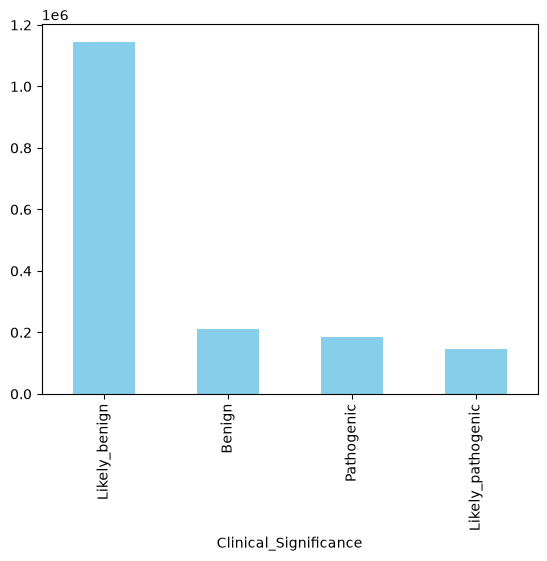

In [44]:
# Define the mapping dictionary to collapse compound labels
clnsig_4way_mapping = {
    'Benign': 'Benign',
    'Benign/Likely_benign': 'Likely_benign',
    'Likely_benign': 'Likely_benign',
    'Pathogenic': 'Pathogenic',
    'Pathogenic/Likely_pathogenic': 'Likely_pathogenic',
    'Likely_pathogenic': 'Likely_pathogenic'
}

# Apply the mapping to your target column
data_ready['Clinical_Significance'] = data_ready['CLNSIG'].map(clnsig_4way_mapping)

# Check the new distribution
print(data_ready['Clinical_Significance'].value_counts())
data_ready['Clinical_Significance'].value_counts().plot(kind='bar', color='skyblue')

Clinical_Significance
Benign        1354594
Pathogenic     332200
Name: count, dtype: int64


<Axes: xlabel='Clinical_Significance'>

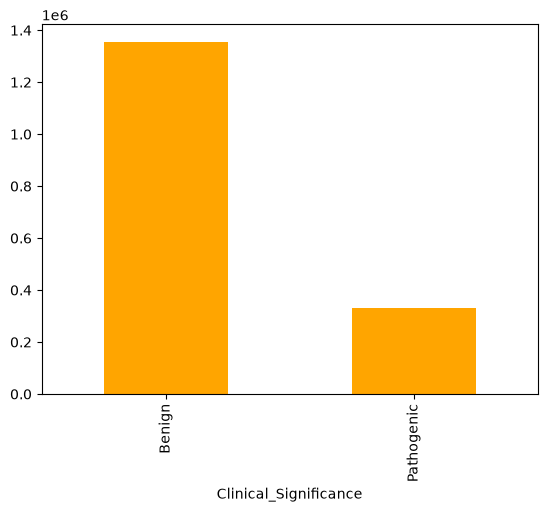

In [77]:
# Define the mapping dictionary to collapse compound labels
clnsig_2way_mapping = {
    'Benign': 'Benign',
    'Benign/Likely_benign': 'Benign',
    'Likely_benign': 'Benign',
    'Pathogenic': 'Pathogenic',
    'Pathogenic/Likely_pathogenic': 'Pathogenic',
    'Likely_pathogenic': 'Pathogenic'
}

# creating a dataframe
bi_data_ready = data_ready.copy()

# Apply the mapping to your target column
bi_data_ready['Clinical_Significance'] = data_ready['CLNSIG'].map(clnsig_2way_mapping)

# Check the new distribution
print(bi_data_ready['Clinical_Significance'].value_counts())
bi_data_ready['Clinical_Significance'].value_counts().plot(kind='bar', color='orange')

## Missing Value
#### Find out how many missing values exist in each column

In [84]:
# data_ready = data_ready.drop(columns=['MC', 'GENEINFO'])
# bi_data_ready = bi_data_ready.drop(columns=['MC', 'GENEINFO'])
bi_data_ready = bi_data_ready.drop(columns=['CLNSIG'])

In [82]:
print(data_ready.isnull().sum())

CHROM                    0
POS                      0
REF                      0
ALT                      0
CLNSIG                   0
CLNVC                    0
AF_EXAC                  0
AF_TGP                   0
AF_ESP                   0
Primary_Gene             0
MC_Clean                 0
Clinical_Significance    0
Target                   0
dtype: int64


### Proportions of Unknown Molecular Consequence across each row

In [46]:
variant_proportions = pd.crosstab(data_ready['MC_Clean'], data_ready['Clinical_Significance'], normalize='index') * 100
print(variant_proportions.round(2))

Clinical_Significance                Benign  Likely_benign  Likely_pathogenic  \
MC_Clean                                                                        
3_prime_UTR_variant                   46.09          52.81               0.26   
5_prime_UTR_variant                   16.75          82.03               0.66   
Unknown                               44.28          36.09               7.01   
frameshift_variant                     0.34           0.66              30.18   
genic_downstream_transcript_variant   19.52          27.62              14.29   
genic_upstream_transcript_variant     57.61          30.83               3.47   
inframe_deletion                      10.98          30.42              33.92   
inframe_indel                          3.05          18.02              44.04   
inframe_insertion                     20.35          39.62              21.93   
initiator_codon_variant                3.57           8.24              38.42   
intron_variant              

--- MC_Clean: 19 unique values ---
MC_Clean
synonymous_variant               522240
intron_variant                   516965
missense_variant                 218688
frameshift_variant               124270
non-coding_transcript_variant    104741
Name: count, dtype: int64




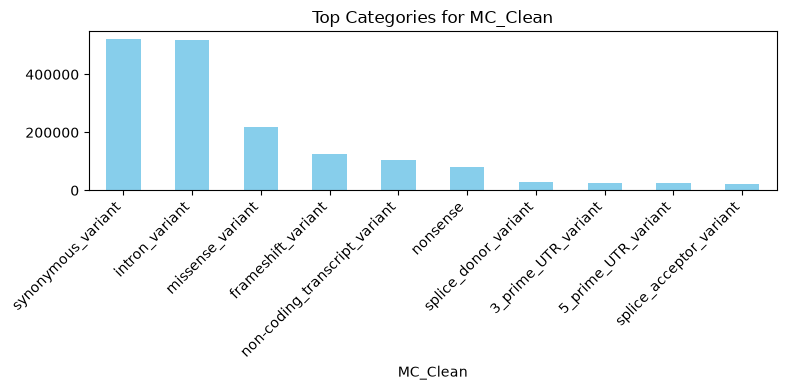

--- Clinical_Significance: 4 unique values ---
Clinical_Significance
Likely_benign        1144932
Benign                209662
Pathogenic            185024
Likely_pathogenic     147176
Name: count, dtype: int64




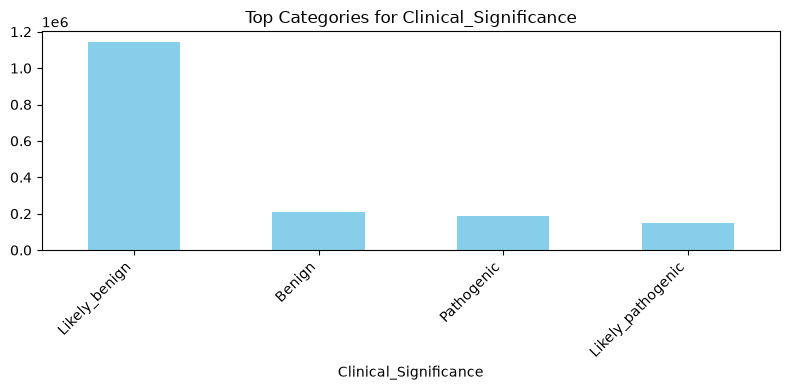

--- CLNVC: 8 unique values ---
CLNVC
single_nucleotide_variant    1467332
Deletion                      120401
Duplication                    53463
Microsatellite                 25335
Insertion                      10662
Name: count, dtype: int64




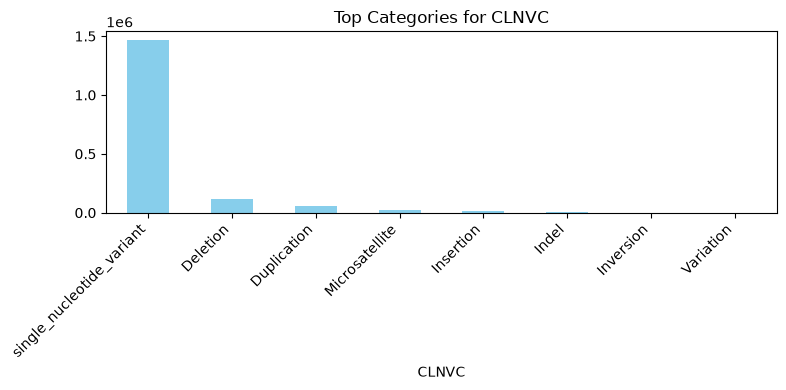

--- Primary_Gene: 16783 unique values ---
Primary_Gene
TTN      22980
BRCA2    11226
NF1       9666
ATM       9305
NEB       8010
Name: count, dtype: int64




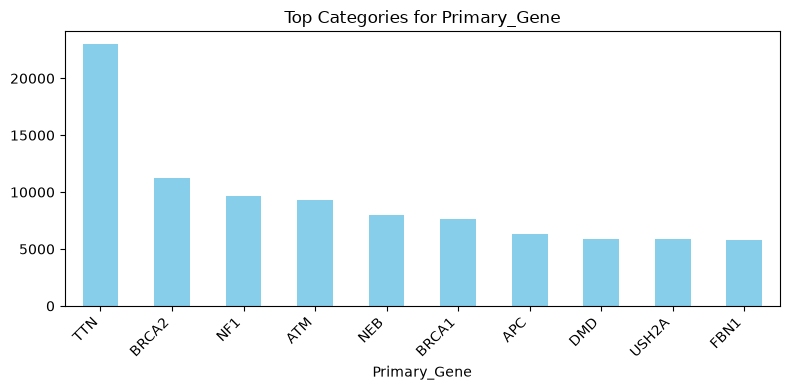

--- CHROM: 27 unique values ---
CHROM
2     165198
1     145351
17    104713
11     96784
3      89909
Name: count, dtype: int64




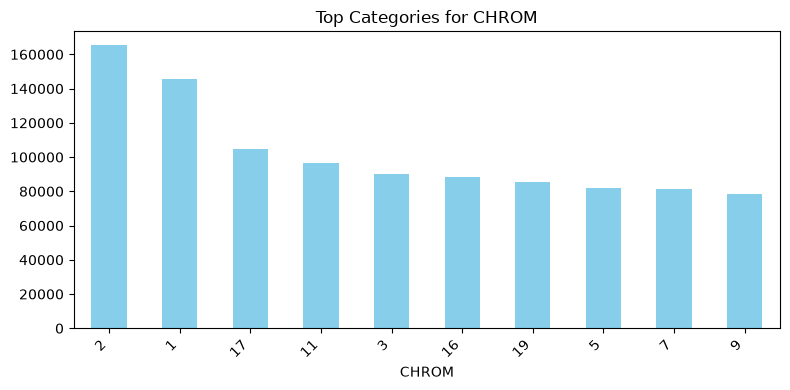

In [47]:
for col in ['MC_Clean', 'Clinical_Significance', 'CLNVC', 'Primary_Gene', 'CHROM']:
    print(f"--- {col}: {data_ready[col].nunique()} unique values ---")
    print(data_ready[col].value_counts().head(5))
    print("\n")
    
    # Create a new figure for each column, plotting only the top 10 categories
    plt.figure(figsize=(8, 4))
    data_ready[col].value_counts().head(10).plot(kind='bar', color='skyblue')
    plt.title(f"Top Categories for {col}")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

In [48]:
# 1. Mapping target to numeric values
target_mapping = {
    'Benign': 0, 
    'Likely_benign': 1, 
    'Likely_pathogenic': 2, 
    'Pathogenic': 3
}

target_col = 'Clinical_Significance' 

if target_col in data_ready.columns:
    data_ready['Target'] = data_ready[target_col].map(target_mapping)

# 2. Selecting only numeric columns from dataframe
numeric_df = data_ready.select_dtypes(include=['number'])

In [83]:
# 1. Mapping target to numeric values
target_mapping = {
    'Benign': 0, 
    'Pathogenic': 1
}

target_col = 'Clinical_Significance' 

if target_col in data_ready.columns:
    bi_data_ready['Target'] = bi_data_ready[target_col].map(target_mapping)

# 2. Selecting only numeric columns from dataframe
numeric_df = bi_data_ready.select_dtypes(include=['number'])

In [85]:
# display(data_ready.head(10))
display(bi_data_ready.head(10))

,CHROM,POS,REF,ALT,CLNVC,AF_EXAC,AF_TGP,AF_ESP,Primary_Gene,MC_Clean,Clinical_Significance,Target
0,1,69134,A,G,single_nucleotide_variant,0.00000,0.0,0.0,OR4F5,missense_variant,Benign,0
1,1,744664,T,TGGTCAATCA,Insertion,0.00000,0.0,0.0,LINC01409,Unknown,Benign,0
2,1,859898,G,C,single_nucleotide_variant,0.00000,0.0,0.0,SAMD11,synonymous_variant,Benign,0
3,1,861336,C,T,single_nucleotide_variant,0.00000,0.0,0.0,SAMD11,synonymous_variant,Benign,0
4,1,861349,C,T,single_nucleotide_variant,0.00033,0.0,0.0,SAMD11,missense_variant,Benign,0
5,1,861360,C,T,single_nucleotide_variant,0.00000,0.0,0.0,SAMD11,synonymous_variant,Benign,0
6,1,861366,C,T,single_nucleotide_variant,0.00000,0.0,0.0,SAMD11,synonymous_variant,Benign,0
7,1,861390,G,T,single_nucleotide_variant,0.00000,0.0,0.0,SAMD11,synonymous_variant,Benign,0
8,1,861402,C,G,single_nucleotide_variant,0.00000,0.0,0.0,SAMD11,intron_variant,Benign,0
9,1,861405,G,A,single_nucleotide_variant,0.00000,0.0,0.0,SAMD11,intron_variant,Benign,0


# Separate features and target

In [51]:
features = ['CHROM', 'POS', 'AF_EXAC', 'AF_TGP', 'AF_ESP', 'CLNVC', 'MC_Clean', 'Primary_Gene']
target = 'Target'

X = data_ready[features].copy()
y = data_ready[target].copy()

In [86]:
features = ['CHROM', 'POS', 'AF_EXAC', 'AF_TGP', 'AF_ESP', 'CLNVC', 'MC_Clean', 'Primary_Gene']
target = 'Target'

X2 = bi_data_ready[features].copy()
y2 = bi_data_ready[target].copy()

In [87]:
# display(X.head(10))
display(X2.head(10))

,CHROM,POS,AF_EXAC,AF_TGP,AF_ESP,CLNVC,MC_Clean,Primary_Gene
0,1,69134,0.00000,0.0,0.0,single_nucleotide_variant,missense_variant,OR4F5
1,1,744664,0.00000,0.0,0.0,Insertion,Unknown,LINC01409
2,1,859898,0.00000,0.0,0.0,single_nucleotide_variant,synonymous_variant,SAMD11
3,1,861336,0.00000,0.0,0.0,single_nucleotide_variant,synonymous_variant,SAMD11
4,1,861349,0.00033,0.0,0.0,single_nucleotide_variant,missense_variant,SAMD11
5,1,861360,0.00000,0.0,0.0,single_nucleotide_variant,synonymous_variant,SAMD11
6,1,861366,0.00000,0.0,0.0,single_nucleotide_variant,synonymous_variant,SAMD11
7,1,861390,0.00000,0.0,0.0,single_nucleotide_variant,synonymous_variant,SAMD11
8,1,861402,0.00000,0.0,0.0,single_nucleotide_variant,intron_variant,SAMD11
9,1,861405,0.00000,0.0,0.0,single_nucleotide_variant,intron_variant,SAMD11


### One-hot encoding all categorical text columns

In [53]:
X_e = pd.get_dummies(X, columns=['CHROM', 'CLNVC', 'MC_Clean'], drop_first=True)
X_e['Primary_Gene_Freq'] = X_e['Primary_Gene'].map(X_e['Primary_Gene'].value_counts())
X_e = X_e.drop(columns=['Primary_Gene'])

print("Original feature count:", X.shape[1])
print("Encoded feature count (after expanding categories):", X_e.shape[1])

Original feature count: 8
Encoded feature count (after expanding categories): 56


In [88]:
X2_e = pd.get_dummies(X2, columns=['CHROM', 'CLNVC', 'MC_Clean'], drop_first=True)
X2_e['Primary_Gene_Freq'] = X2_e['Primary_Gene'].map(X2_e['Primary_Gene'].value_counts())
X2_e = X2_e.drop(columns=['Primary_Gene'])

print("Original feature count:", X2.shape[1])
print("Encoded feature count (after expanding categories):", X2_e.shape[1])

Original feature count: 8
Encoded feature count (after expanding categories): 56


In [89]:
pd.set_option('display.max_columns', None)
# display(X_e.head(10))
display(X2_e.head(10))

,POS,AF_EXAC,AF_TGP,AF_ESP,CHROM_10,CHROM_11,CHROM_12,CHROM_13,CHROM_14,CHROM_15,CHROM_16,CHROM_17,CHROM_18,CHROM_19,CHROM_2,CHROM_20,CHROM_21,CHROM_22,CHROM_3,CHROM_4,CHROM_5,CHROM_6,CHROM_7,CHROM_8,CHROM_9,CHROM_MT,CHROM_NW_003315925.1,CHROM_NW_003315947.1,CHROM_X,CHROM_Y,CLNVC_Duplication,CLNVC_Indel,CLNVC_Insertion,CLNVC_Inversion,CLNVC_Microsatellite,CLNVC_Variation,CLNVC_single_nucleotide_variant,MC_Clean_5_prime_UTR_variant,MC_Clean_Unknown,MC_Clean_frameshift_variant,MC_Clean_genic_downstream_transcript_variant,MC_Clean_genic_upstream_transcript_variant,MC_Clean_inframe_deletion,MC_Clean_inframe_indel,MC_Clean_inframe_insertion,MC_Clean_initiator_codon_variant,MC_Clean_intron_variant,MC_Clean_missense_variant,MC_Clean_no_sequence_alteration,MC_Clean_non-coding_transcript_variant,MC_Clean_nonsense,MC_Clean_splice_acceptor_variant,MC_Clean_splice_donor_variant,MC_Clean_stop_lost,MC_Clean_synonymous_variant,Primary_Gene_Freq
0,69134,0.00000,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,1
1,744664,0.00000,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,1
2,859898,0.00000,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,527
3,861336,0.00000,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,527
4,861349,0.00033,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,527
5,861360,0.00000,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,527
6,861366,0.00000,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,527
7,861390,0.00000,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,527
8,861402,0.00000,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,527
9,861405,0.00000,0.0,0.0,False,False,False,False,False,False,Fal

In [55]:
!pip install seaborn

### Checking the final spread

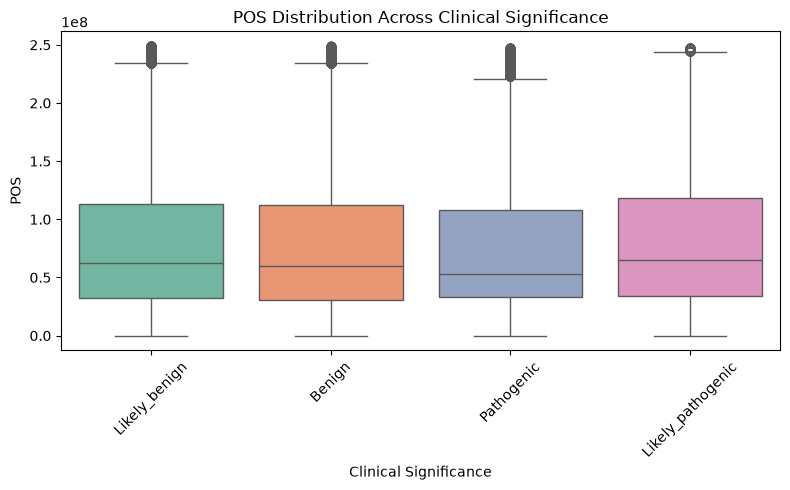

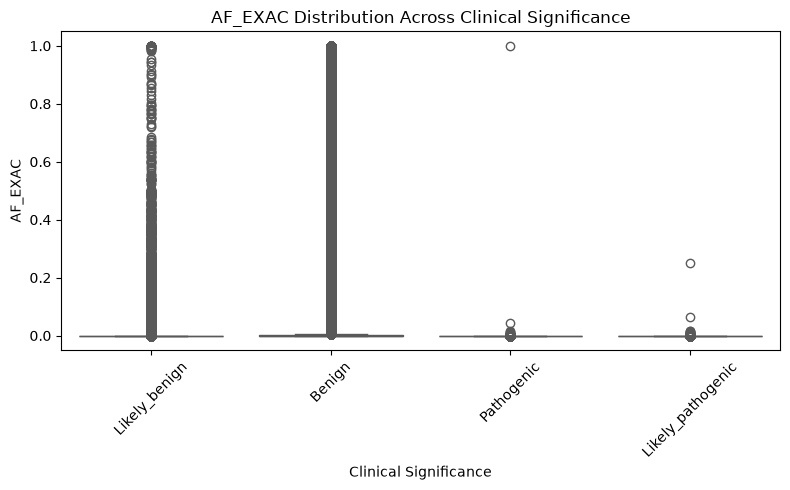

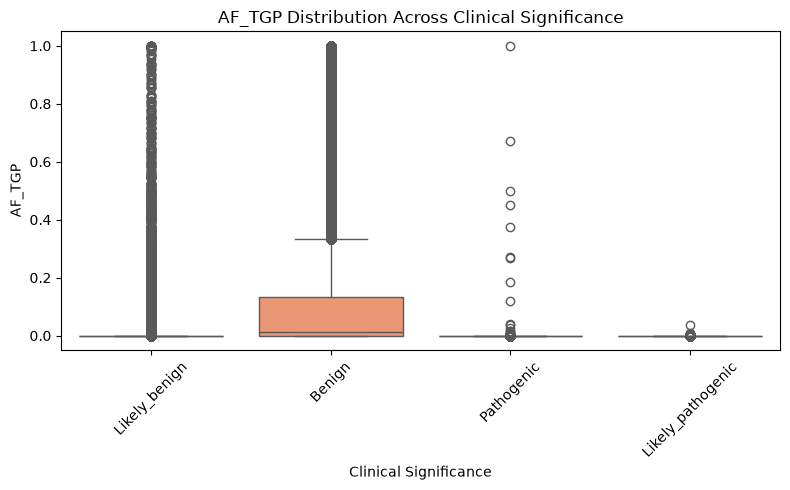

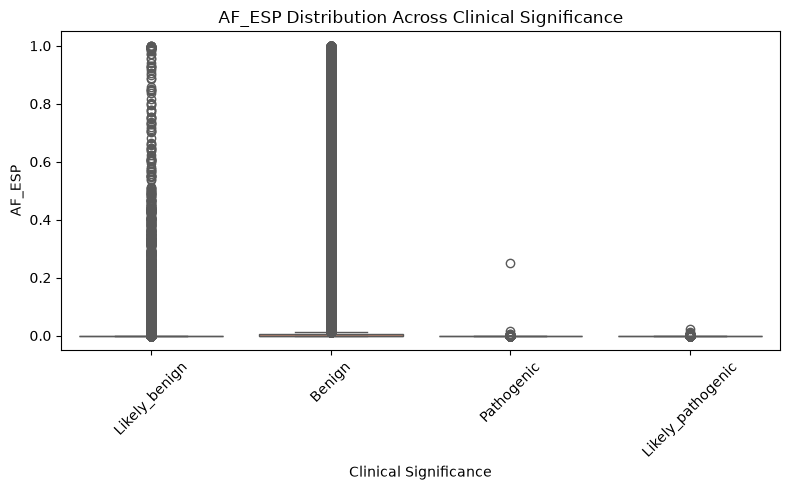

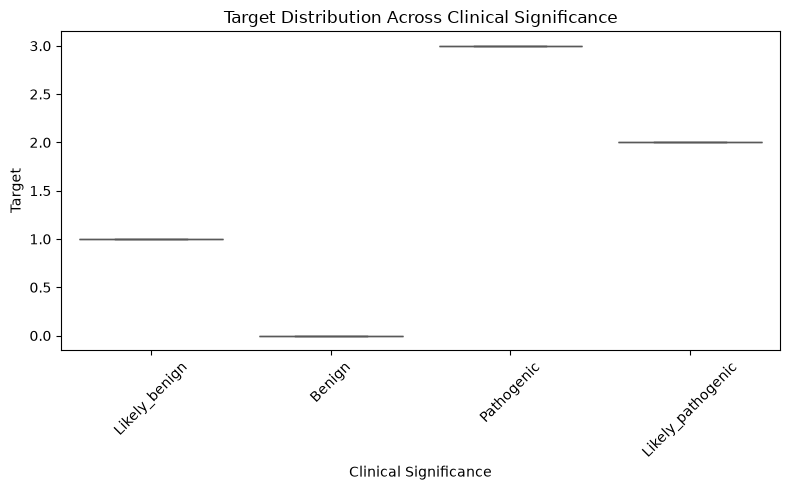

In [56]:
import seaborn as sns
num_cols = data_ready.select_dtypes(include=['number']).columns

# Looping through each numerical feature 
for col in num_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(
        x='Clinical_Significance', 
        y=col, 
        data=data_ready, 
        hue='Clinical_Significance', 
        palette='Set2', 
        legend=False
    )
    plt.title(f'{col} Distribution Across Clinical Significance')
    plt.xlabel('Clinical Significance')
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Feature Importance

In [57]:
import scipy.stats as stats

# Automatically find all numeric columns except the target itself
numeric_features = data_ready.select_dtypes(include=['number']).columns.drop('Target', errors='ignore')

for col in numeric_features:
    # Group the values of this feature by your clinical significance groups
    groups = [group[col].dropna().values for _, group in data_ready.groupby('Clinical_Significance')]
    
    # Run ANOVA
    f_val, p_val = stats.f_oneway(*groups)
    print(f"Feature: {col:<10} | F-value: {f_val:8.4f} | P-value: {p_val:.4e}")

Feature: POS        | F-value: 502.3683 | P-value: 0.0000e+00
Feature: AF_EXAC    | F-value: 36017.9638 | P-value: 0.0000e+00
Feature: AF_TGP     | F-value: 148445.6544 | P-value: 0.0000e+00
Feature: AF_ESP     | F-value: 40770.5491 | P-value: 0.0000e+00


# Train test Split

In [58]:
from sklearn.model_selection import train_test_split

# Split into 70% training and 30% testing (stratified to maintain class balance)
X_train, X_test, y_train, y_test = train_test_split(X_e, y, test_size=0.3, random_state=42, stratify=y)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (1180755, 56)
Testing set shape: (506039, 56)


In [90]:
from sklearn.model_selection import train_test_split

# Split into 70% training and 30% testing (stratified to maintain class balance)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2_e, y2, test_size=0.3, random_state=42, stratify=y2)

print("Training set shape:", X2_train.shape)
print("Testing set shape:", X2_test.shape)

Training set shape: (1180755, 56)
Testing set shape: (506039, 56)


# Model Training

### Training the Random Forest Model

### 4-way problem

In [101]:
rf_model = RandomForestClassifier(random_state=42, class_weight='balanced_subsample', n_estimators=150, n_jobs=-1)

# Fitting the Random forest model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

# Evaluating Th Random Forest model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8558668403028226

Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.73      0.75     62899
           1       0.94      0.95      0.94    343480
           2       0.55      0.55      0.55     44153
           3       0.67      0.66      0.66     55507

    accuracy                           0.86    506039
   macro avg       0.73      0.72      0.73    506039
weighted avg       0.85      0.86      0.85    506039



### Binary Problem

In [96]:
rf2_model = RandomForestClassifier(random_state=42, class_weight='balanced_subsample', n_estimators=100, n_jobs=-1)

# Fitting the Random forest model
rf2_model.fit(X2_train, y2_train)

# Make predictions
y2_pred = rf2_model.predict(X2_test)

# Evaluating Th Random Forest model
print("Accuracy:", accuracy_score(y2_test, y2_pred))
print("\nClassification Report:\n", classification_report(y2_test, y2_pred))

Accuracy: 0.9799778277958814

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99    406379
           1       0.95      0.95      0.95     99660

    accuracy                           0.98    506039
   macro avg       0.97      0.97      0.97    506039
weighted avg       0.98      0.98      0.98    506039



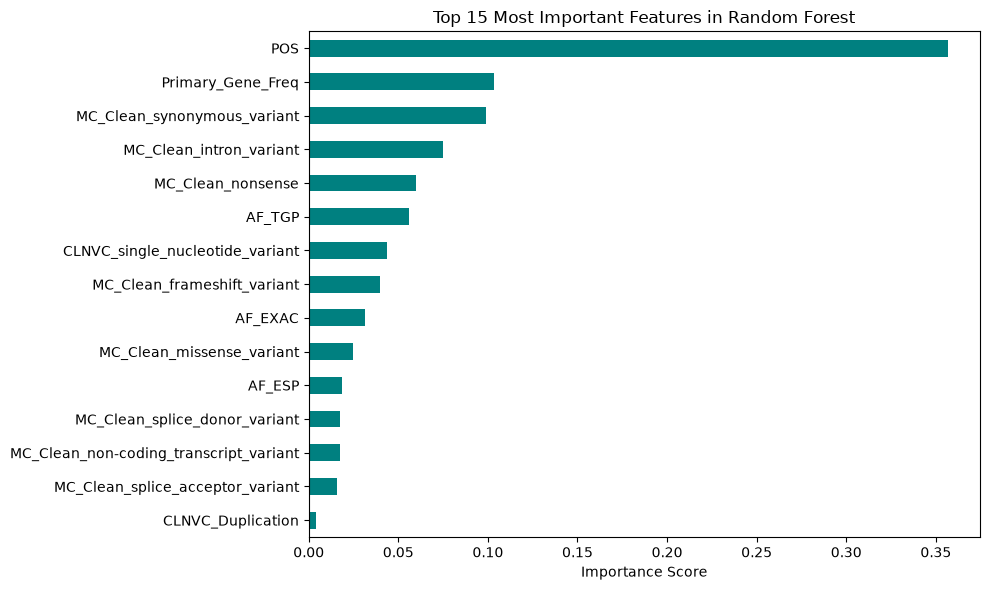

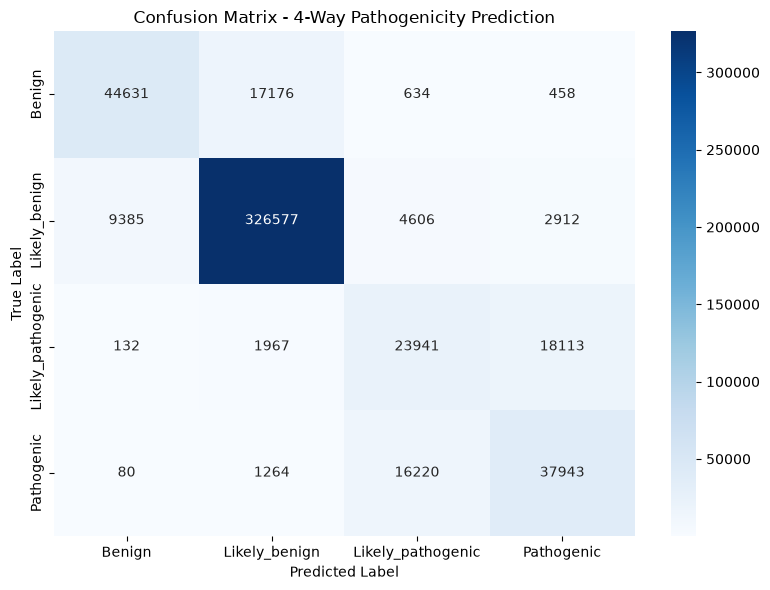

In [100]:
from sklearn.metrics import confusion_matrix

importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)

# Plot Top 15 Feature Importances
plt.figure(figsize=(10, 6))
importances.sort_values(ascending=False).head(15).plot(kind='barh', color='teal')
plt.title("Top 15 Most Important Features in Random Forest")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()  
plt.tight_layout()
plt.show()

print("============================="*5)

#Plot Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Benign', 'Likely_benign', 'Likely_pathogenic', 'Pathogenic'],
            yticklabels=['Benign', 'Likely_benign', 'Likely_pathogenic', 'Pathogenic'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - 4-Way Pathogenicity Prediction')
plt.tight_layout()
plt.show()

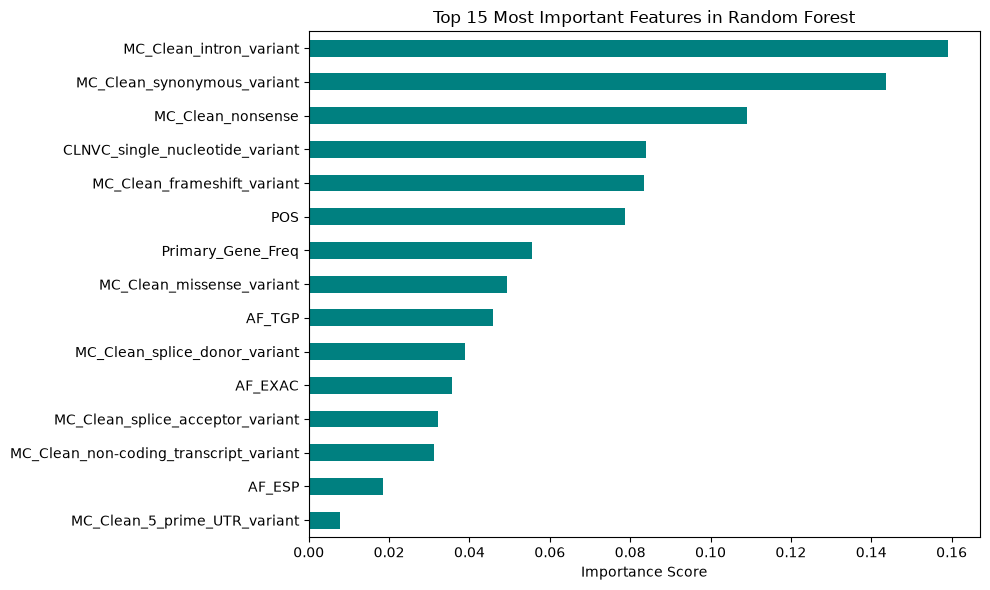

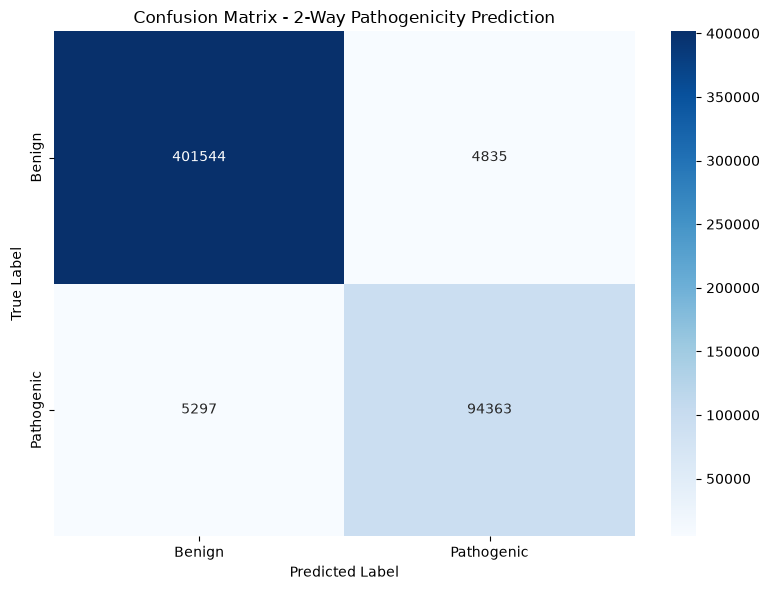

In [97]:
from sklearn.metrics import confusion_matrix

importances2 = pd.Series(rf2_model.feature_importances_, index=X_train.columns)

# Plot Top 15 Feature Importances
plt.figure(figsize=(10, 6))
importances2.sort_values(ascending=False).head(15).plot(kind='barh', color='teal')
plt.title("Top 15 Most Important Features in Random Forest")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()  
plt.tight_layout()
plt.show()

print("============================="*5)

#Plot Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y2_test, y2_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Benign','Pathogenic'],
            yticklabels=['Benign', 'Pathogenic'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - 2-Way Pathogenicity Prediction')
plt.tight_layout()
plt.show()

### Training XGBoost Model

In [74]:
!pip install xgboost

In [73]:
from xgboost import XGBClassifier
from sklearn.utils import compute_sample_weight

# Computing class weights
sample_weights = compute_sample_weight(
    class_weight='balanced', 
    y=y_train
)

xgb_model = XGBClassifier(random_state=42, n_estimators=100, n_jobs=-1)

# Fitting the XG Bosst model
xgb_model.fit(X_train, y_train, sample_weight=sample_weights)

# Make predictions
y_pred = xgb_model.predict(X_test)

# Evaluating The XG Boost model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8244858597855106

Classification Report:
               precision    recall  f1-score   support

           0       0.61      0.88      0.72     62899
           1       0.97      0.86      0.91    343480
           2       0.48      0.60      0.53     44153
           3       0.71      0.75      0.73     55507

    accuracy                           0.82    506039
   macro avg       0.69      0.77      0.72    506039
weighted avg       0.86      0.82      0.83    506039



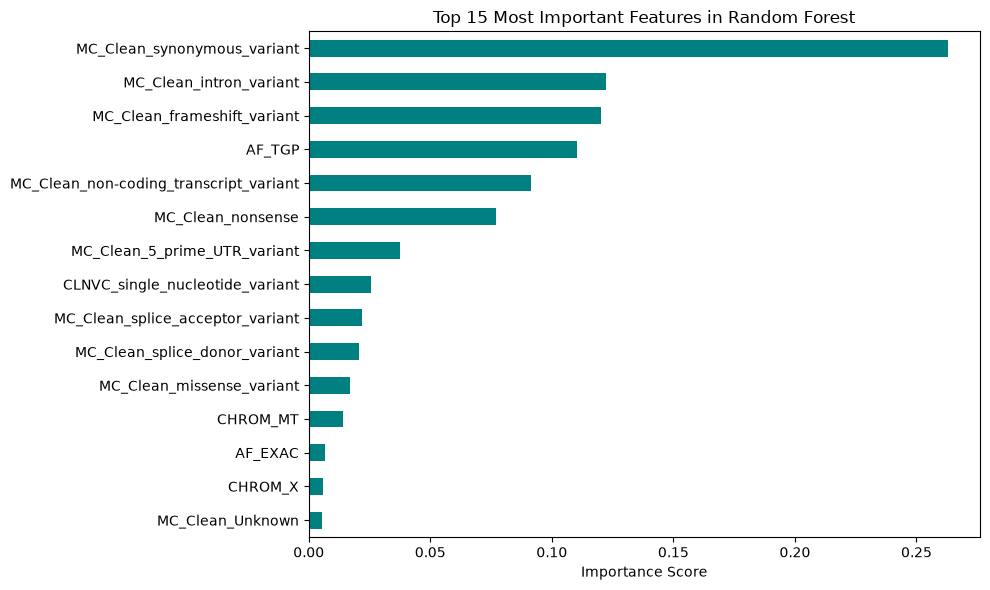

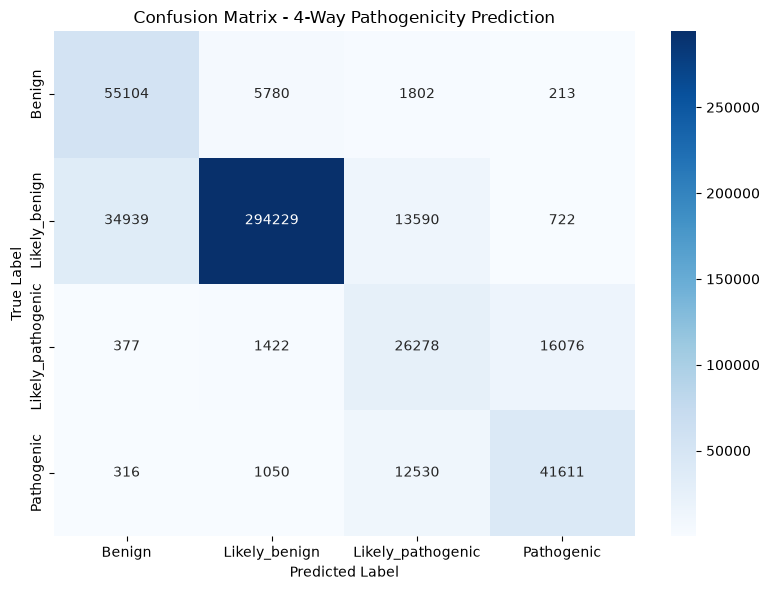

In [75]:
from sklearn.metrics import confusion_matrix

importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns)

# Plot Top 15 Feature Importances
plt.figure(figsize=(10, 6))
importances.sort_values(ascending=False).head(15).plot(kind='barh', color='teal')
plt.title("Top 15 Most Important Features in Random Forest")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()  
plt.tight_layout()
plt.show()

print("============================="*5)

#Plot Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Benign', 'Likely_benign', 'Likely_pathogenic', 'Pathogenic'],
            yticklabels=['Benign', 'Likely_benign', 'Likely_pathogenic', 'Pathogenic'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - 4-Way Pathogenicity Prediction')
plt.tight_layout()
plt.show()

## Training a Feed Forward Neural Network

In [66]:
!pip install torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 4.9 MB/s eta 0:00:00m eta 0:00:010:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 4.9 MB/s eta 0:00:00m eta 0:00:010:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 5.6 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 5.6 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 6.1 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 5.1 MB/s eta 0:00:00m eta 0:00:010:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 6.3 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 5.9 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 5.6 MB/s eta 0:00:00m eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 5.2 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━

In [106]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Convert pandas/numpy data to PyTorch Tensors
# Force conversion to float32 NumPy array first, then to PyTorch Tensor
X_train_tensor = torch.tensor(X_train.values.astype(np.float32))
y_train_tensor = torch.tensor(y_train.values.astype(np.int64))

X_test_tensor = torch.tensor(X_test.values.astype(np.float32))
y_test_tensor = torch.tensor(y_test.values.astype(np.int64))

# Create DataLoaders for batching
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Define the FFN Architecture
class FFN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(FFN, self).__init__()
        self.layer1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3) # Helps prevent overfitting
        self.layer2 = nn.Linear(hidden_dim, output_dim)
        
    def forward(self, x):
        x = self.layer1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.layer2(x)
        return x

In [107]:
# Determine input and output dimensions dynamically
input_dim = X_train_tensor.shape[1]
output_dim = len(np.unique(y_train)) # Number of classes
hidden_dim = 64

ffn_model = FFN(input_dim, hidden_dim, output_dim)

# Define Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(ffn_model.parameters(), lr=0.001)

In [108]:
# 4. Training Loop
epochs = 20
ffn_model.train()

for epoch in range(epochs):
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = ffn_model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

# Evaluation
ffn_model.eval()
with torch.no_grad():
    test_outputs = ffn_model(X_test_tensor)
    _, y_pred = torch.max(test_outputs, 1)
    
# Convert back to numpy for sklearn metrics
y_pred_np = y_pred.numpy()
y_test_np = y_test_tensor.numpy()

print("Accuracy:", accuracy_score(y_test_np, y_pred_np))
print("\nClassification Report:\n", classification_report(y_test_np, y_pred_np))

Accuracy: 0.6787638897397236

Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.00      0.00     62899
           1       0.68      1.00      0.81    343480
           2       0.00      0.00      0.00     44153
           3       0.00      0.00      0.00     55507

    accuracy                           0.68    506039
   macro avg       0.29      0.25      0.20    506039
weighted avg       0.52      0.68      0.55    506039



/home/lakki4403/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/lakki4403/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/lakki4403/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.sh

In [104]:
print("Non-numeric columns still in X_train:")
print(X_train.select_dtypes(include=['object', 'category']).columns)

Non-numeric columns still in X_train:
Index([], dtype='object')
